# Additional 01 - Promotional placements

Optional context on product-store-week displays and mailer advertising. This is not used by the household risk model or CRM audience selector. Missing promotion records do not establish no promotion, and observed sales shares are not causal lift.

The setup recomputes paid-line history from transaction_data and product metadata; causal_data.csv is required only for this supplementary matching analysis. Run independently from the main notebooks.

**Step 1: Import the required libraries.**

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from matplotlib.ticker import (
    PercentFormatter,
    StrMethodFormatter,
    FuncFormatter,
    MaxNLocator,
)
from IPython.display import display, Markdown


**Step 2: Prepare ROOT, imports, imports.**

In [2]:
ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook inside the project.")
sys.path.insert(0, str(ROOT / "src"))
from retail_customer_360.metrics import load_transactions, build_metrics, summary
from retail_customer_360.promotions import add_eda_sources, build_promotion_match

pd.set_option("display.max_columns", 25)


**Step 3: Prepare FIGURES.**

In [3]:
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "additional/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, TEAL = "#245C83", "#D77931", "#208778"


**Step 4: Define the run_sql helper.**

In [4]:
def run_sql(query):
    display(Markdown("```sql\n" + query.strip() + "\n```"))
    frame = con.execute(query).fetchdf()
    display(frame)
    return frame


**Step 5: Define the finish_figure helper.**

In [5]:
from IPython.display import Image as NotebookImage


def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=160, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 6: Load data and inspect the input.**

In [6]:
con = load_transactions(ROOT)
first_day, last_day = con.execute("""SELECT min(day),max(day)
FROM raw_transactions""").fetchone()
WINDOW_START_DAY = first_day
AS_OF_DAY = last_day
build_metrics(con, WINDOW_START_DAY, AS_OF_DAY, ROOT)
add_eda_sources(con, ROOT, include_placements=True)
base_summary = summary(con, ROOT)
assert (
    con.execute("""SELECT count(*),sum(sales_value)
FROM eda_lines""").fetchone()
    == con.execute("""SELECT count(*),sum(sales_value)
FROM eligible_lines""").fetchone()
)


**Step 7: Check the calculation.**

In [7]:
assert con.execute("""SELECT count(*)
FROM discount_baskets""").fetchone()[0] == base_summary["purchase_baskets"]
window_label = f"Source days {WINDOW_START_DAY} to {AS_OF_DAY}; eligible paid lines"
print(window_label)
print("Category/discount counts and exact sales reconcile with notebook 02.")


Source days 1 to 711; eligible paid lines
Category/discount counts and exact sales reconcile with notebook 02.


## 4. Check the product-store-week key before joining placements

Scan the promotion source, retaining only keys needed by eligible paid lines. This is a **relevant-key uniqueness audit**, not a global uniqueness test of all 36.8 million source records. Missing required identifiers in eligible transactions are rejected.

Group matching promotion rows by product, store and source week. Keep a placement only for a key with exactly one source row. Mark duplicate keys as ambiguous (even if their codes agree); do not silently select one or expand transaction rows. Missing promotion records remain `not_recorded`, distinct from the explicit code `0`.

This scan can take time; it is the only large promotion-file scan in this notebook.

**Step 8: Calculate and inspect query results.**

In [8]:
build_promotion_match(con)
promotion_key_quality = run_sql(
    "SELECT\n    (SELECT count(*) FROM needed_promotion_keys) AS "
    "required_product_store_weeks,\n    count(*) AS "
    "keys_with_source_records,\n    count(*) FILTER (WHERE "
    "source_rows>1) AS ambiguous_keys,\n    "
    "coalesce(sum(source_rows),0) AS relevant_source_rows,\n    "
    "max(source_rows) AS max_rows_per_key FROM "
    "promotion_key_audit"
)


```sql
SELECT
    (SELECT count(*) FROM needed_promotion_keys) AS required_product_store_weeks,
    count(*) AS keys_with_source_records,
    count(*) FILTER (WHERE source_rows>1) AS ambiguous_keys,
    coalesce(sum(source_rows),0) AS relevant_source_rows,
    max(source_rows) AS max_rows_per_key FROM promotion_key_audit
```

,required_product_store_weeks,keys_with_source_records,ambiguous_keys,relevant_source_rows,max_rows_per_key
0,2355132,480597,614,481211.0,2


**Step 9: Calculate and inspect query results.**

In [9]:
promotion_coverage = run_sql("""SELECT match_status,count(*) AS eligible_lines,
       sum(sales_value) AS sales,
       100.0*sum(sales_value)/
  (SELECT sum(sales_value)
   FROM eda_lines) AS sales_share_pct
FROM eda_promotion_lines
GROUP BY match_status
ORDER BY match_status""")
assert (
    con.execute("""SELECT count(*),sum(sales_value)
FROM eda_lines""").fetchone()
    == con.execute("""SELECT count(*),sum(sales_value)
FROM eda_promotion_lines""").fetchone()
)
print("Promotion join preserves exact line count and sales.")


```sql
SELECT match_status,count(*) AS eligible_lines,
       sum(sales_value) AS sales,
       100.0*sum(sales_value)/
  (SELECT sum(sales_value)
   FROM eda_lines) AS sales_share_pct
FROM eda_promotion_lines
GROUP BY match_status
ORDER BY match_status
```

,match_status,eligible_lines,sales,sales_share_pct
0,ambiguous_key,856,1478.14,0.018345
1,matched_unique,559746,1556269.77,19.314684
2,not_recorded,2016213,6499695.89,80.666971


Promotion join preserves exact line count and sales.


## 5. Sales composition alongside placement codes

The charts show **shares of eligible sales**, not treatment effects or per-exposure lift. All groups, including absent and ambiguous records, stay visible. They describe purchased products only: promotion keys with zero observed purchases are not part of this analytical population. Code `0` is the documented absence of that placement; a missing source record is a separate condition.

A higher sales share can reflect assortment, number of product-store-weeks, category prices or targeting. It cannot establish that moving a product caused more sales. Code meanings are listed in the [data dictionary](../../docs/data_dictionary.md).

**Step 10: Calculate and inspect query results.**

In [10]:
display_sales = run_sql(
    "SELECT display_code AS code,count(*) AS "
    "eligible_lines,\n    count(DISTINCT (product_id,store_id,"
    "week_no)) AS purchase_observed_keys,\n    sum(sales_value) "
    "AS sales,\n    100.0*sum(sales_value)/(SELECT "
    "sum(sales_value) FROM eda_lines) AS sales_share_pct\nFROM "
    "eda_promotion_lines GROUP BY display_code ORDER BY sales "
    "DESC"
)


```sql
SELECT display_code AS code,count(*) AS eligible_lines,
    count(DISTINCT (product_id,store_id,week_no)) AS purchase_observed_keys,
    sum(sales_value) AS sales,
    100.0*sum(sales_value)/(SELECT sum(sales_value) FROM eda_lines) AS sales_share_pct
FROM eda_promotion_lines GROUP BY display_code ORDER BY sales DESC
```

,code,eligible_lines,purchase_observed_keys,sales,sales_share_pct
0,[Not recorded],2016213,1874535,6499695.89,80.666971
1,0,288338,244724,833295.44,10.341933
2,7,54620,44937,134924.34,1.674530
3,2,40557,35216,125493.43,1.557484
4,9,38215,32466,108137.64,1.342084
5,5,39357,36028,103770.92,1.287889
6,3,39314,33823,100370.48,1.245686
7,6,17411,15644,55462.42,0.688338
8,1,19403,16924,44637.69,0.553993
9,A,15216,13695,29439.17,0.365366


**Step 11: Calculate and inspect query results.**

In [11]:
mailer_sales = run_sql(
    "SELECT mailer_code AS code,count(*) AS eligible_lines,\n    "
    "count(DISTINCT (product_id,store_id,week_no)) AS "
    "purchase_observed_keys,\n    sum(sales_value) AS "
    "sales,\n    100.0*sum(sales_value)/(SELECT sum(sales_value) "
    "FROM eda_lines) AS sales_share_pct\nFROM "
    "eda_promotion_lines GROUP BY mailer_code ORDER BY sales DESC"
)


```sql
SELECT mailer_code AS code,count(*) AS eligible_lines,
    count(DISTINCT (product_id,store_id,week_no)) AS purchase_observed_keys,
    sum(sales_value) AS sales,
    100.0*sum(sales_value)/(SELECT sum(sales_value) FROM eda_lines) AS sales_share_pct
FROM eda_promotion_lines GROUP BY mailer_code ORDER BY sales DESC
```

,code,eligible_lines,purchase_observed_keys,sales,sales_share_pct
0,[Not recorded],2016213,1874535,6499695.89,80.666971
1,A,211011,193097,613399.35,7.612828
2,0,149077,132667,405070.91,5.027288
3,D,128043,94817,352205.66,4.371184
4,H,27050,23368,77176.69,0.957831
5,F,30096,23409,69905.51,0.867589
6,C,4236,3417,12423.74,0.154190
7,L,3952,3578,11388.82,0.141345
8,J,4462,4070,10058.09,0.124830
9,X,1536,1347,3966.95,0.049233


**Step 12: Prepare display labels.**

In [12]:
display_labels = {
    "0": "0: No extra display",
    "1": "1: Store front",
    "2": "2: Store rear",
    "3": "3: Front endcap",
    "4": "4: Mid-area endcap",
    "5": "5: Rear endcap",
    "6": "6: Side-aisle endcap",
    "7": "7: In aisle",
    "9": "9: Secondary display",
    "A": "A: In shelf",
}


**Step 13: Build the chart.**

In [13]:
mailer_labels = {
    "0": "0: No mailer ad",
    "A": "A: Inside feature",
    "C": "C: Inside item listing",
    "D": "D: Front-page feature",
    "F": "F: Back-page feature",
    "H": "H: Wrap-front feature",
    "J": "J: Inside-wrap coupon",
    "L": "L: Wrap-back feature",
    "P": "P: Inside-page coupon",
    "X": "X: Inside-page free offer",
    "Z": "Z: Front/back/wrap free offer",
}
fig = Figure(figsize=(15, 7))
axes = fig.subplots(1, 2)


**Step 14: Finish and display the chart.**

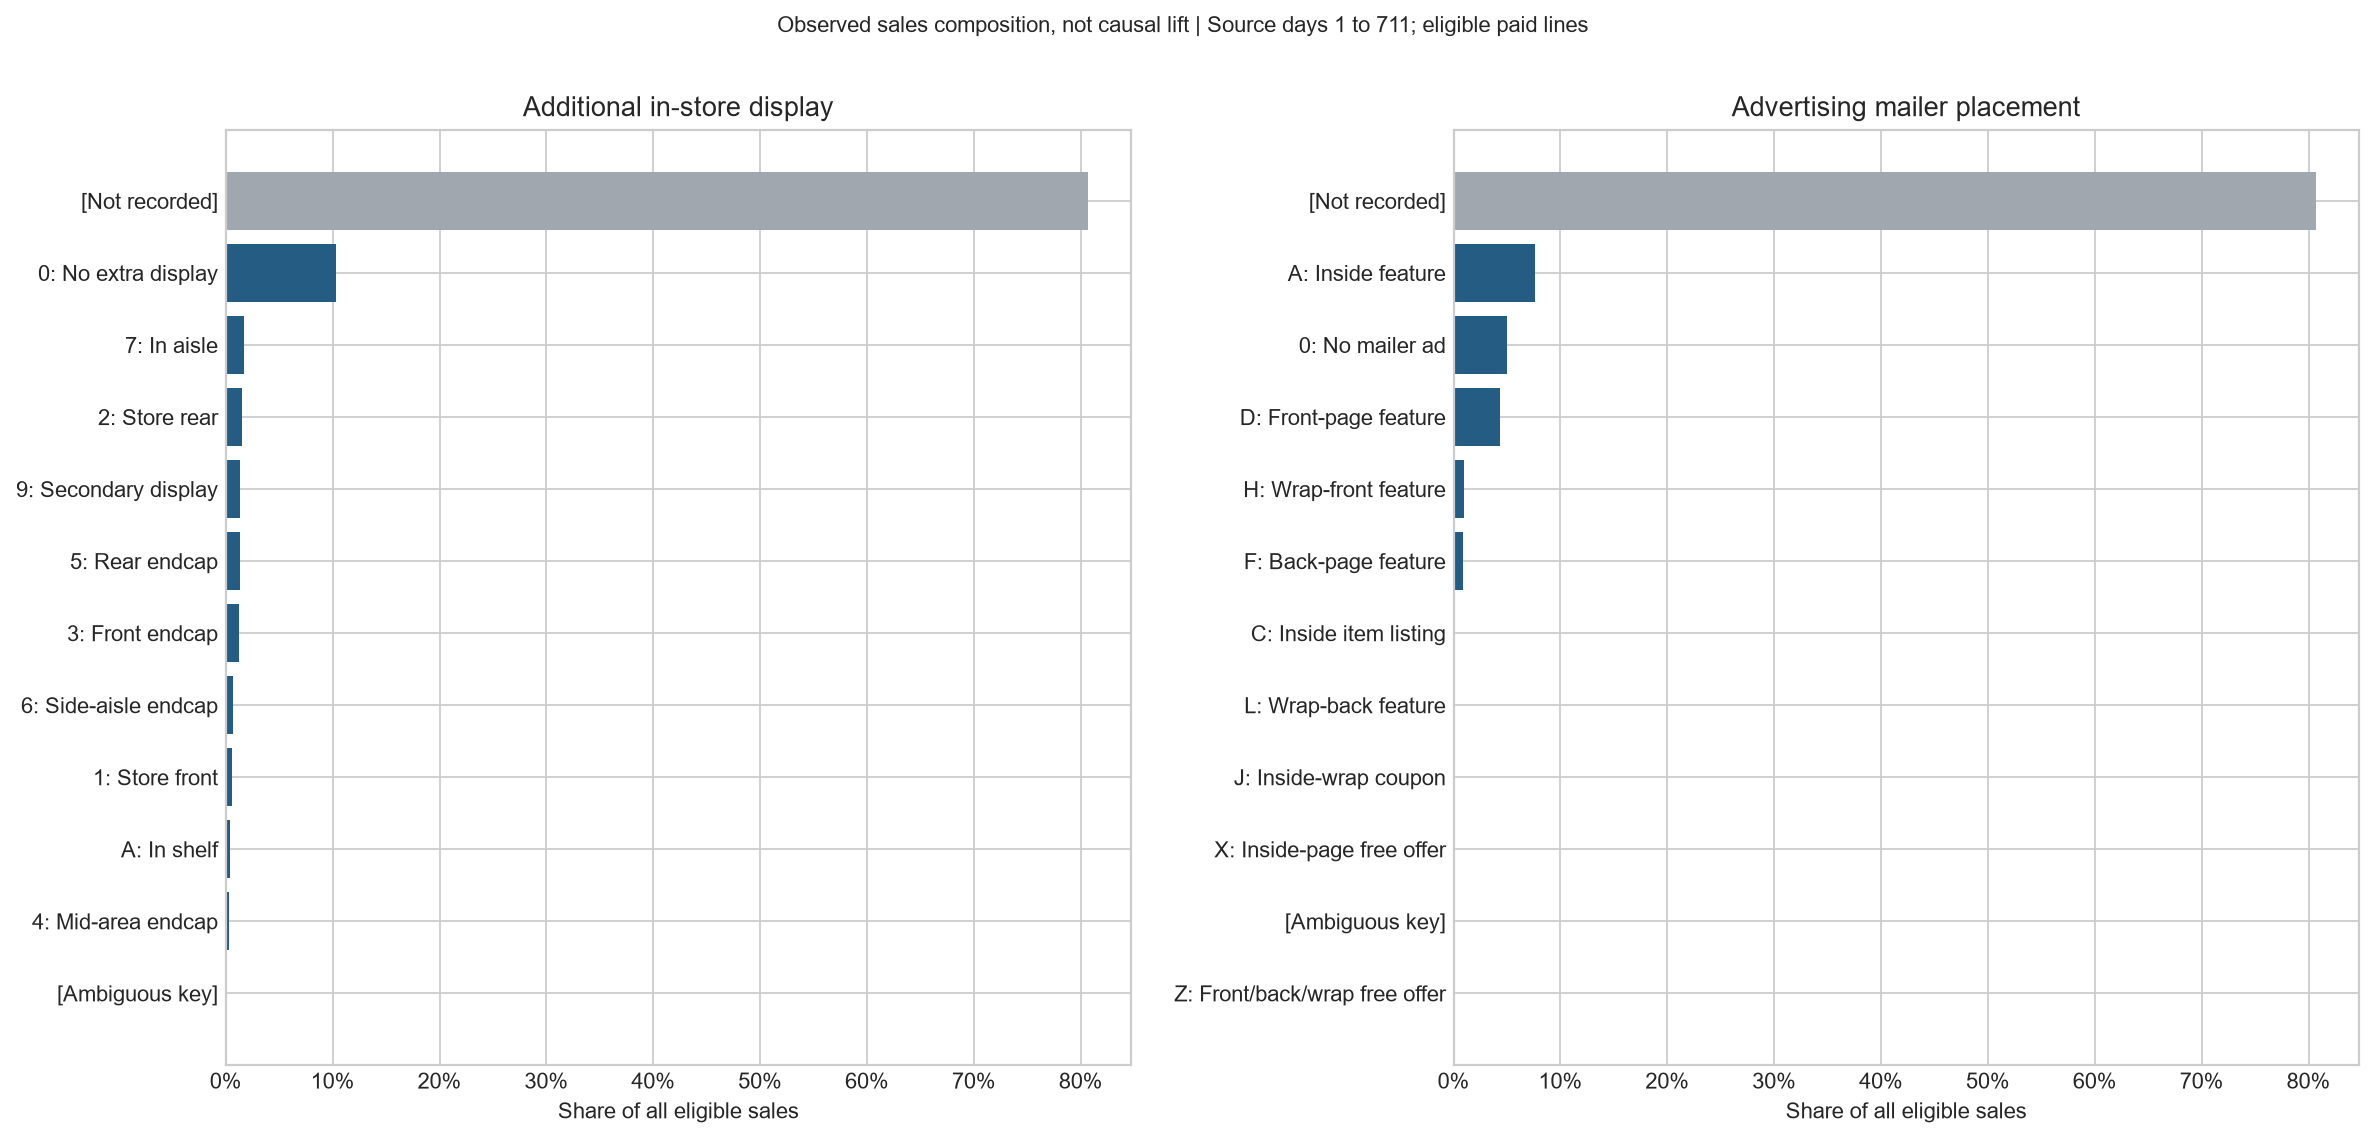

In [14]:
for ax, frame, labels, title in [
    (axes[0], display_sales, display_labels, "Additional in-store display"),
    (axes[1], mailer_sales, mailer_labels, "Advertising mailer placement"),
]:
    frame = frame.iloc[::-1]
    names = [labels.get(str(c), str(c)) for c in frame.code]
    colors = ["#A0A7AE" if str(c).startswith("[") else BLUE for c in frame.code]
    ax.barh(names, frame.sales_share_pct, color=colors)
    ax.set(xlabel="Share of all eligible sales", title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
fig.suptitle(
    "Observed sales composition, not causal lift | " + window_label, fontsize=10, y=1.01
)
finish_figure(fig, "03_placement_sales_composition.png")


**Step 15: Prepare unknown display, unknown mailer.**

In [15]:
unknown_display = sorted(
    set(display_sales.code)
    - set(display_labels)
    - {"[Not recorded]", "[Ambiguous key]", "[Missing code]"}
)
unknown_mailer = sorted(
    set(mailer_sales.code)
    - set(mailer_labels)
    - {"[Not recorded]", "[Ambiguous key]", "[Missing code]"}
)
print("Unrecognised display codes:", unknown_display)
print("Unrecognised mailer codes:", unknown_mailer)


Unrecognised display codes: []
Unrecognised mailer codes: []


## Reconcile and export placement aggregates

Only needed product-store-week keys are audited. Data exports remain local; placement figures are kept in additional/figures.

In [16]:
before = con.execute("""SELECT count(*),sum(sales_value)
FROM eda_lines""").fetchone()
after = con.execute("""SELECT count(*),sum(sales_value)
FROM eda_promotion_lines""").fetchone()
assert before == after
out = ROOT / "data/processed/eda"
out.mkdir(parents=True, exist_ok=True)
for name, frame in {
    "promotion_key_quality": promotion_key_quality,
    "promotion_coverage": promotion_coverage,
    "display_sales": display_sales,
    "mailer_sales": mailer_sales,
}.items():
    frame.to_csv(out / (name + ".csv"), index=False)
print("Counts and sales preserved; optional placement aggregates saved.")
con.close()


Counts and sales preserved; optional placement aggregates saved.
